In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

os.listdir("/content/drive/MyDrive")

['Colab Notebooks', 'DEEPGUARD']

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [ ]:
import os

print(os.listdir("/content/drive"))

['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


In [ ]:
print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'DEEPGUARD']


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/DEEPGUARD"))

['Dataset', 'model']


In [ ]:
print(os.listdir("/content/drive/MyDrive/DEEPGUARD/Dataset"))

['WELFake_Dataset.csv']


In [ ]:
import pandas as pd
import numpy as np
import re
import joblib

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
df = pd.read_csv(
    "/content/drive/MyDrive/DEEPGUARD/Dataset/WELFake_Dataset.csv"
)

print(df.shape)

(72134, 4)


In [ ]:
print(df.columns)

df.head()

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df = df.dropna()

df["content"] = df["title"] + " " + df["text"]

df = df[["content", "label"]]

print(df.shape)

(71537, 2)


In [ ]:
print(df.columns)

Index(['content', 'label'], dtype='object')


In [ ]:
X = df["content"]
y = df["label"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(57229,)
(14308,)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape)
print(X_test_vec.shape)

(57229, 5000)
(14308, 5000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_vec, y_train)

log_pred = log_model.predict(X_test_vec)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, log_pred))

print(classification_report(y_test, log_pred))

Logistic Regression Accuracy: 0.9435979871400615
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      7006
           1       0.94      0.95      0.95      7302

    accuracy                           0.94     14308
   macro avg       0.94      0.94      0.94     14308
weighted avg       0.94      0.94      0.94     14308



In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_vec, y_train)

nb_pred = nb_model.predict(X_test_vec)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred))

print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.846729102599944
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      7006
           1       0.83      0.87      0.85      7302

    accuracy                           0.85     14308
   macro avg       0.85      0.85      0.85     14308
weighted avg       0.85      0.85      0.85     14308



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_vec, y_train)

svm_pred = svm_model.predict(X_test_vec)

print("Linear SVM Accuracy:",
      accuracy_score(y_test, svm_pred))

print(classification_report(y_test, svm_pred))

Linear SVM Accuracy: 0.9500978473581213
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      7006
           1       0.94      0.96      0.95      7302

    accuracy                           0.95     14308
   macro avg       0.95      0.95      0.95     14308
weighted avg       0.95      0.95      0.95     14308



In [ ]:
print("Logistic Regression:",
      accuracy_score(y_test, log_pred))

print("Naive Bayes:",
      accuracy_score(y_test, nb_pred))

print("Linear SVM:",
      accuracy_score(y_test, svm_pred))

Logistic Regression: 0.9435979871400615
Naive Bayes: 0.846729102599944
Linear SVM: 0.9500978473581213


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.943598
1,Naive Bayes,0.846729
2,Linear SVM,0.950098


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

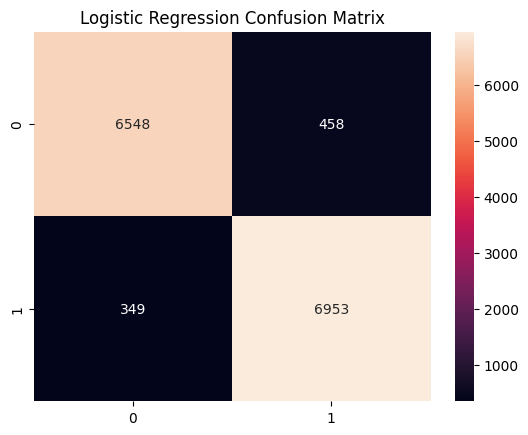

In [ ]:
cm_log = confusion_matrix(y_test, log_pred)
sns.heatmap(cm_log, annot=True, fmt="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

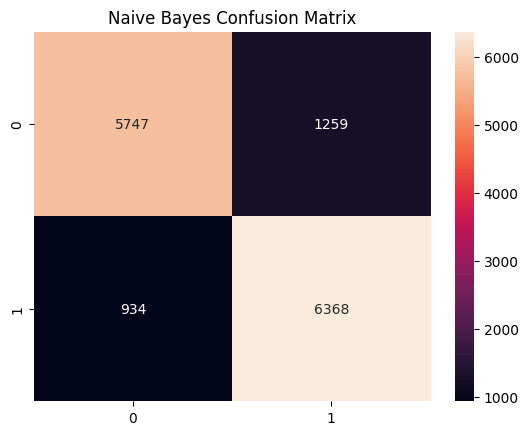

In [ ]:
cm_nb = confusion_matrix(y_test, nb_pred)
sns.heatmap(cm_nb, annot=True, fmt="d")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

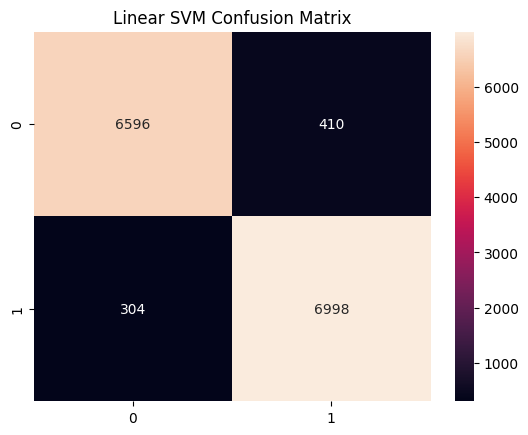

In [ ]:
cm_svm = confusion_matrix(y_test, svm_pred)
sns.heatmap(cm_svm, annot=True, fmt="d")
plt.title("Linear SVM Confusion Matrix")
plt.show()



In [ ]:
print([var for var in globals().keys() if "tfidf" in var or "vect" in var])

['vectorizer']


In [ ]:
import joblib

joblib.dump(svm_model, "deepguard_svm_model.pkl")
joblib.dump(vectorizer, "deepguard_vectorizer.pkl")

['deepguard_vectorizer.pkl']

In [ ]:
def predict_deepguard(text):
    vec = vectorizer.transform([text])
    pred = svm_model.predict(vec)[0]

    if pred == 1:
        return "⚠️ Toxic Content"
    else:
        return "✅ Safe Content"

In [ ]:
joblib.dump(svm_model, "deepguard_svm_model.pkl")
joblib.dump(vectorizer, "deepguard_vectorizer.pkl")

['deepguard_vectorizer.pkl']

In [ ]:
import os
print(os.getcwd())

/content


In [ ]:
import os
print(os.listdir())

['.config', 'drive', 'deepguard_vectorizer.pkl', 'deepguard_svm_model.pkl', 'sample_data']


In [ ]:
import os

print(os.path.abspath("deepguard_vectorizer.pkl"))

/content/deepguard_vectorizer.pkl


In [ ]:
from google.colab import files
files.download("deepguard_vectorizer.pkl")
files.download("deepguard_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/deepguard_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
os.listdir("/content")

['.config',
 'drive',
 'deepguard_vectorizer.pkl',
 'deepguard_svm_model.pkl',
 'sample_data']

In [ ]:
from google.colab import files

files.download("/content/deepguard_vectorizer.pkl")
files.download("/content/deepguard_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, svm_pred)

print(cm)

[[6596  410]
 [ 304 6998]]


In [ ]:
import joblib

joblib.dump(
    svm_model,
    "/content/drive/MyDrive/DEEPGUARD/model/text_model.pkl"
)

joblib.dump(
    vectorizer,
    "/content/drive/MyDrive/DEEPGUARD/model/vectorizer.pkl"
)

print("DeepGuard Text Model Saved Successfully 🚀")

DeepGuard Text Model Saved Successfully 🚀


In [ ]:
import re

def predict_text(text):

    cleaned = re.sub(r'[^a-zA-Z\s]', ' ', text.lower())

    vectorized = vectorizer.transform([cleaned])

    prediction = svm_model.predict(vectorized)[0]

    if prediction == 1:
        return "FAKE 🔴"
    else:
        return "REAL 🟢"

In [ ]:
print(predict_text(
    "Government announces new education policy for universities."
))

FAKE 🔴


In [ ]:
print(predict_text(
    "BREAKING! Share this before it gets deleted!"
))

FAKE 🔴


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/DEEPGUARD/model"))

['text_model.pkl', 'vectorizer.pkl']
